# Experimenting with MNIST dataset

## Loading MNIST

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml( "mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff")

print(mnist.keys())

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])


In [3]:
X, Y = mnist.data, mnist.target
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(70000, 784))

In [4]:
print(X.shape)
print(Y.shape)

(70000, 784)
(70000,)


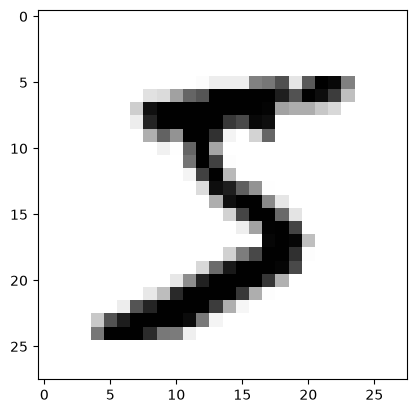

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

def plotDigit(data):
    image = data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.plot()
    
plotDigit(X[0])

## Splitting data

In [16]:
x_train, x_test, y_train, y_test = X[:60000], X[60000:], Y[:60000], Y[:60000]

print(len(x_train))

60000


In [17]:
y_train_5 = (y_train == '5')
y_test_5 = (y_test == '5')

print(y_train_5[0])

True


## Training SGD Classifier

In [7]:
from sklearn.linear_model import SGDClassifier

sgd_classifier  = SGDClassifier()

sgd_classifier.fit(x_train, y_train_5)

,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if th

In [8]:
sgd_classifier.predict([x_train[0], x_train[1], x_train[2], x_train[3], x_train[4]])

array([ True, False, False, False, False])

In [9]:
print([y_train_5[0], y_train_5[1], y_train_5[2], y_train_5[3], y_train_5[4]])

[np.True_, np.False_, np.False_, np.False_, np.False_]


In [10]:
from sklearn.model_selection import cross_val_score

score = cross_val_score(sgd_classifier, x_train, y_train_5, scoring="accuracy", cv=3)
print(score)

[0.96005 0.956   0.94475]


In [11]:
from sklearn.dummy import DummyClassifier

dc = DummyClassifier()
score = cross_val_score(dc, x_train, y_train_5, cv=3)
print(score)

[0.90965 0.90965 0.90965]


In [12]:
scores = sgd_classifier.decision_function(x_train)

print(scores)

[  2213.77496943 -10483.66580475 -12212.25668557 ...   5950.28104825
  -4150.63500531  -4357.77180068]


In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

scores = cross_val_predict(sgd_classifier, x_train, y_train_5, cv=3, method='decision_function')

precisions, recalls, thresholds = precision_recall_curve(y_train_5, scores)

print(scores)


[   875.21211088 -12666.32850057 -23480.05634837 ...  13388.33972525
  -6080.82475398  -9871.12735928]


[]

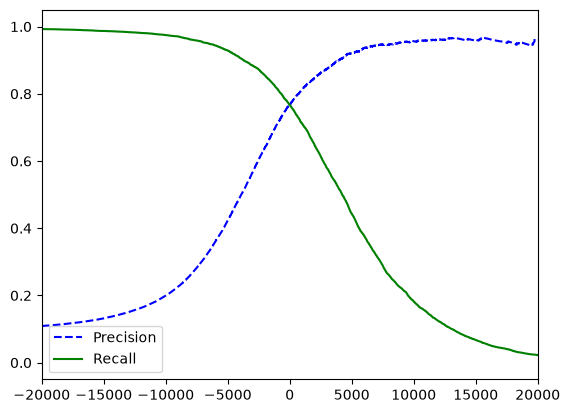

In [14]:
plt.plot(thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(thresholds, recalls[:-1], "g-", label="Recall")
plt.xlim(-20000, 20000)
plt.legend()
plt.plot()

In [15]:
from sklearn.metrics import roc_curve

fpr, tpr, thres = roc_curve(y_train_5, scores)

[]

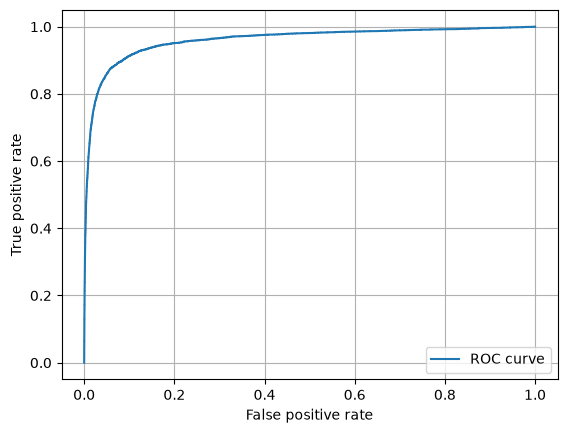

In [16]:
plt.plot(fpr, tpr, label="ROC curve")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.grid(visible=True)
plt.legend()
plt.plot()

[]

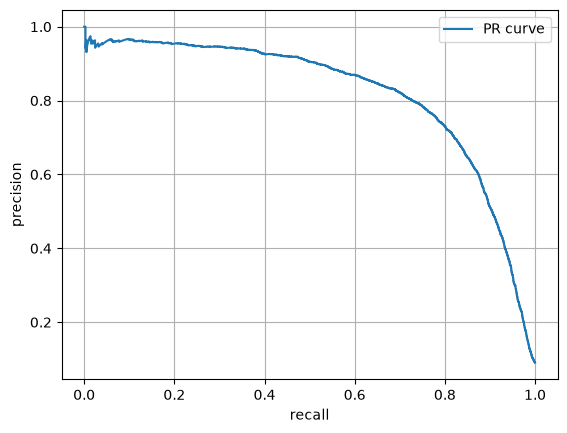

In [17]:
plt.plot(recalls, precisions, label="PR curve")
plt.xlabel("recall")
plt.ylabel("precision")
plt.grid(visible=True)
plt.legend()
plt.plot()

In [18]:
from sklearn.metrics import confusion_matrix, classification_report

pred = cross_val_predict(sgd_classifier, x_train, y_train_5, cv=3,)

cm = confusion_matrix(y_train_5, pred)
cr = classification_report(y_train_5, pred)

print("Confusion Matrix")
print(cm)
print("\nClassification Report")
print(cr)

Confusion Matrix
[[53614   965]
 [ 1703  3718]]

Classification Report
              precision    recall  f1-score   support

       False       0.97      0.98      0.98     54579
        True       0.79      0.69      0.74      5421

    accuracy                           0.96     60000
   macro avg       0.88      0.83      0.86     60000
weighted avg       0.95      0.96      0.95     60000



## Training Random Forest Classifier

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(random_state=42, )


pred = cross_val_predict(rf_classifier, x_train, y_train_5, cv=3,)

cm = confusion_matrix(y_train_5, pred)
cr = classification_report(y_train_5, pred)

print("Confusion Matrix")
print(cm)
print("\nClassification Report")
print(cr)


Confusion Matrix
[[54534    45]
 [  725  4696]]

Classification Report
              precision    recall  f1-score   support

       False       0.99      1.00      0.99     54579
        True       0.99      0.87      0.92      5421

    accuracy                           0.99     60000
   macro avg       0.99      0.93      0.96     60000
weighted avg       0.99      0.99      0.99     60000



In [20]:

scores = cross_val_predict(rf_classifier, x_train, y_train_5, cv=3, method="predict_proba")

print(score[:5])


[0.90965 0.90965 0.90965]


In [21]:
print(scores[:5])


[[0.11 0.89]
 [0.99 0.01]
 [0.96 0.04]
 [1.   0.  ]
 [0.99 0.01]]


In [22]:
y_score = scores[:,1]
print(y_score)

[0.89 0.01 0.04 ... 0.98 0.08 0.06]


[]

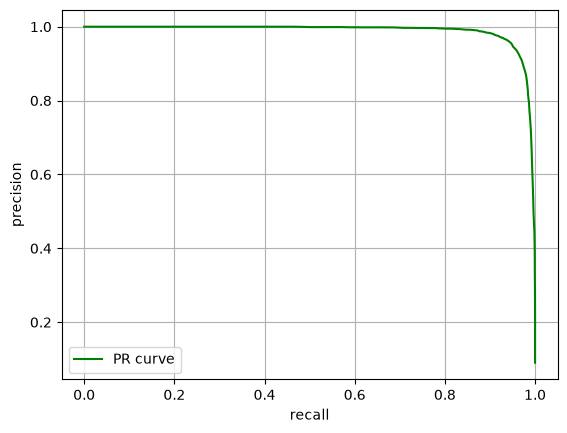

In [23]:


precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_score)

plt.plot(recalls, precisions, "g-", label="PR curve")
plt.xlabel("recall")
plt.ylabel("precision")
plt.grid(visible=True)
plt.legend()
plt.plot()

[]

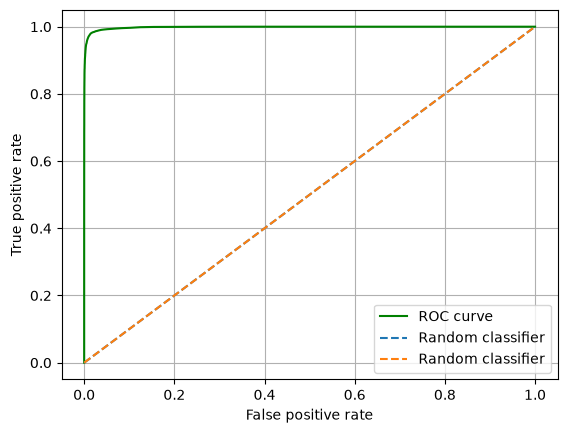

In [24]:
fpr, tpr, thres = roc_curve(y_train_5, y_score)

plt.plot(fpr, tpr,"g-", label="ROC curve")
plt.plot([(0,0),(1,1)],"--", label="Random classifier")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.grid(visible=True)
plt.legend()
plt.plot()



In [25]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_train_5, y_score)

print(f"ROC AUC: {roc_auc}")

ROC AUC: 0.9983436731328145


[]

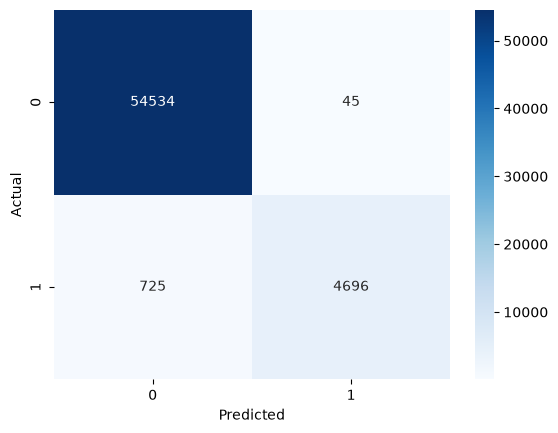

In [26]:
import seaborn as sns

sns.heatmap(cm, cmap="Blues", fmt="d", annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.plot()

## Multinomial Classification

### SGD Classifier

In [27]:
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier

pred_ovr = cross_val_predict(OneVsRestClassifier(sgd_classifier), x_train, y_train, cv=3)
score_ovr = cross_val_predict(OneVsRestClassifier(sgd_classifier), x_train, y_train, cv=3, method="decision_function")

pred_ovo = cross_val_predict(OneVsOneClassifier(sgd_classifier), x_train, y_train, cv=3)
score_ovo = cross_val_predict(OneVsOneClassifier(sgd_classifier), x_train, y_train, cv=3, method="decision_function")


c:\Users\Maaz\Projects\classification-problems\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\Maaz\Projects\classification-problems\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\Maaz\Projects\classification-problems\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\Maaz\Projects\classification-problems\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider incre

In [28]:
print("score Ovr:")
print(score_ovr[:5])

print("score Ovo:")
print(score_ovo[:5])

score Ovr:
[[-25364.9935019  -75925.30470307 -18095.69019187  -4842.52164527
  -41109.81657067   3138.89814857 -33613.83932258 -21202.00249562
  -10730.54330749 -33950.06368911]
 [ 43571.28351689 -75445.30796223 -14930.6240762  -18491.27547147
  -36412.65920546 -23265.26976151 -23128.84905821 -27758.47434151
   -4789.5939738  -25038.60179707]
 [-39192.52310378 -81353.14634218 -18339.93397725  -4601.82323055
    6092.65412645 -28450.54209572 -47153.65887561 -18422.50543886
  -16213.16186253 -28966.8955701 ]
 [-31935.86958046   7527.5242777   -7062.53936104  -2397.56797298
  -16582.33482498 -11485.0530627  -22937.04740036 -20450.61000286
     154.73003658 -16039.24569377]
 [-55504.41787974 -55132.69231259 -38917.32143345 -21017.13365871
  -18330.06248811 -15612.94499509 -32970.99049839 -10291.80166651
   -6536.15796659   4376.33561347]]
score Ovo:
[[0.66666737 4.66666744 4.33332101 8.33333296 0.66666706 9.33333314
  0.66666701 2.66666761 6.33333232 7.33332801]
 [9.33333316 0.66666699 3.6

In [29]:
cm = confusion_matrix(y_train, pred_ovr)
cr = classification_report(y_train, pred_ovr)

print("One v Rest:")
print("Confusion Matrix")
print(cm)
print("\nClassification Report")
print(cr)

One v Rest:
Confusion Matrix
[[5684    1   48   29   10   47   59    4   38    3]
 [   4 6257  223   62    5   18   29   14  124    6]
 [  74   31 5298  178   53   22  116   59  111   16]
 [  43   20  199 5421   16  158   44   53  115   62]
 [  22   23   46   53 5035   19  116   63  158  307]
 [ 124   15   56  362   85 4226  198   21  253   81]
 [  66    8  105   24   67   75 5549    1   21    2]
 [  28   16   87  125   70   21   12 5635   38  233]
 [  99   98  186  415   21  235   91   30 4590   86]
 [  37   28   40  184  232   70    8  356  172 4822]]

Classification Report
              precision    recall  f1-score   support

           0       0.92      0.96      0.94      5923
           1       0.96      0.93      0.95      6742
           2       0.84      0.89      0.87      5958
           3       0.79      0.88      0.84      6131
           4       0.90      0.86      0.88      5842
           5       0.86      0.78      0.82      5421
           6       0.89      0.94     

In [30]:
cm = confusion_matrix(y_train, pred_ovo)
cr = classification_report(y_train, pred_ovo)

print("One v One:")
print("Confusion Matrix")
print(cm)
print("\nClassification Report")
print(cr)

One v One:
Confusion Matrix
[[5685    0   38    9    6   62   59    8   48    8]
 [   1 6500   48   13    9   16    4   18  124    9]
 [  26   36 5423   80   83   23   61   47  169   10]
 [  16   24  197 5265    4  296    7   38  236   48]
 [  10   18   50    3 5428   14   50   30   45  194]
 [  60    8   57  184   24 4765   97   10  167   49]
 [  38    5   71    5   42   50 5662    3   42    0]
 [  12   14   72   45   50   11    2 5770   54  235]
 [  22   78   75  113   18  227   30   20 5196   72]
 [  18   15   37   55  170   50    3  322   72 5207]]

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.96      0.96      5923
           1       0.97      0.96      0.97      6742
           2       0.89      0.91      0.90      5958
           3       0.91      0.86      0.88      6131
           4       0.93      0.93      0.93      5842
           5       0.86      0.88      0.87      5421
           6       0.95      0.96      

### Random Forest

In [32]:
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier

rf_pred_ovr = cross_val_predict(OneVsRestClassifier(rf_classifier), x_train, y_train, cv=3)


In [33]:
rf_pred_ovo = cross_val_predict(OneVsOneClassifier(rf_classifier), x_train, y_train, cv=3)


In [34]:

cm = confusion_matrix(y_train, rf_pred_ovr)
cr = classification_report(y_train, rf_pred_ovr)

print("One v Rest:")
print("Confusion Matrix")
print(cm)
print("\nClassification Report")
print(cr)

One v Rest:
Confusion Matrix
[[5836    2    6    4    8    5   17    2   41    2]
 [   2 6621   48   15   15    0   13   11   14    3]
 [  33   10 5761   31   23    1   15   27   50    7]
 [   7    7   98 5794    5   44   11   57   69   39]
 [   7   12   18    1 5637    0   23   12   17  115]
 [  36    5   11   52   11 5180   65    7   30   24]
 [  18    8    6    0   12   68 5775    0   31    0]
 [   9   25   68    7   37    0    0 6016    9   94]
 [  14   35   45   57   27   47   40   11 5518   57]
 [  21   10   17   71   64   19    3   71   36 5637]]

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      5923
           1       0.98      0.98      0.98      6742
           2       0.95      0.97      0.96      5958
           3       0.96      0.95      0.95      6131
           4       0.97      0.96      0.97      5842
           5       0.97      0.96      0.96      5421
           6       0.97      0.98     

[]

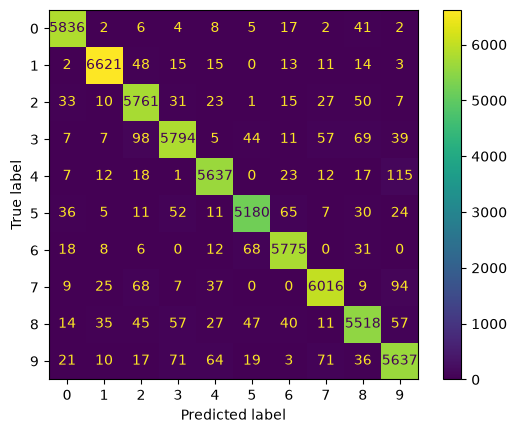

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_train, rf_pred_ovr)
plt.plot()

In [36]:

cm = confusion_matrix(y_train, rf_pred_ovo)
cr = classification_report(y_train, rf_pred_ovo)

print("One v One:")
print("Confusion Matrix")
print(cm)
print("\nClassification Report")
print(cr)

One v One:
Confusion Matrix
[[5815    1   13    1    5   10   15    1   56    6]
 [   1 6600   43   25   12    7   10   11   25    8]
 [  28    6 5731   39   32    8   18   33   53   10]
 [   7   10   84 5772    2   54   11   53   92   46]
 [   7    6   19    3 5646    1   24   14   33   89]
 [  26   11   10   45    9 5197   61    4   39   19]
 [  21   10    5    0   10   53 5769    0   49    1]
 [   6   20   49    6   29    4    0 6040   22   89]
 [   9   32   34   40   20   41   30    7 5582   56]
 [  15   11    8   67   68   17    2   50   48 5663]]

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      5923
           1       0.98      0.98      0.98      6742
           2       0.96      0.96      0.96      5958
           3       0.96      0.94      0.95      6131
           4       0.97      0.97      0.97      5842
           5       0.96      0.96      0.96      5421
           6       0.97      0.97      

[]

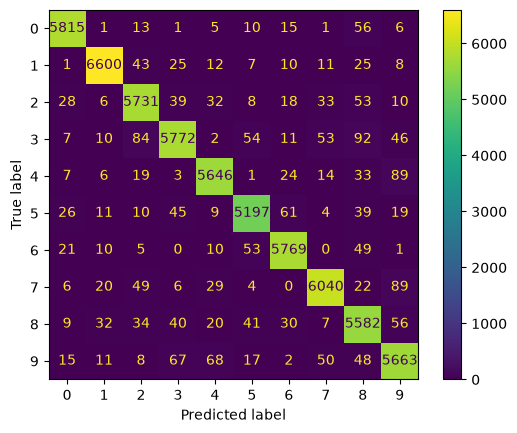

In [38]:
ConfusionMatrixDisplay.from_predictions(y_train, rf_pred_ovo)
plt.plot()

[]

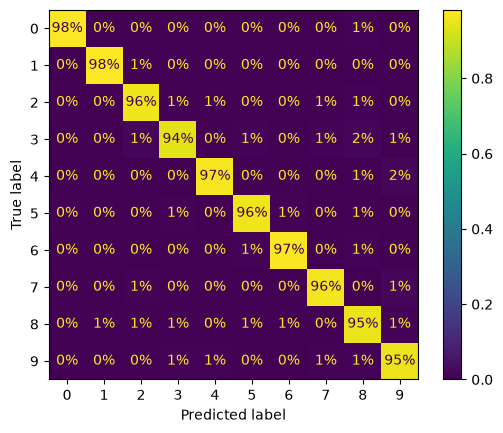

In [40]:
ConfusionMatrixDisplay.from_predictions(y_train, rf_pred_ovo, normalize="true", values_format=".0%")
plt.plot()

[]

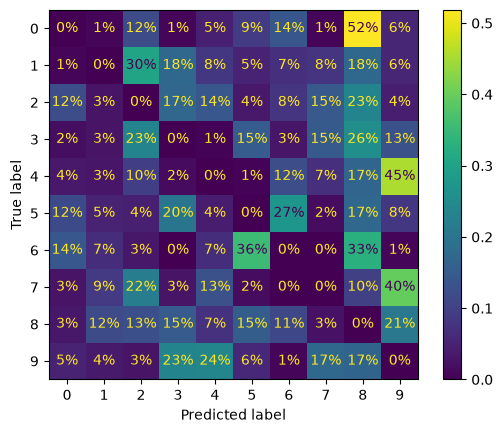

In [41]:
ConfusionMatrixDisplay.from_predictions(y_train, rf_pred_ovo, normalize="true", values_format=".0%", sample_weight=(y_train!=rf_pred_ovo))
plt.plot()

In [45]:
from sklearn.neighbors import KNeighborsClassifier

y_odd = (y_train.astype('int8')%2 == 1)
print(y_odd)

[ True False False ...  True False False]


In [46]:
y_large = (y_train.astype('int8')>=7)
print(y_large)

[False False False ... False False  True]


In [47]:
import numpy as np 

y_multi = np.c_[y_large, y_odd]

print(y_multi)

[[False  True]
 [False False]
 [False False]
 ...
 [False  True]
 [False False]
 [ True False]]


In [50]:
from sklearn.metrics import f1_score

knn = KNeighborsClassifier()

pred = cross_val_predict(knn, x_train, y_multi, cv=3)

f1 = f1_score(y_multi, pred, average="macro")
# cr = classification_report(y_multi, pred)

print("F1 score: ")
print(f1)
# print("\nClassification Report: ")
# print(cr)

F1 score: 
0.9764102655606048


In [ ]:
from sklearn.multioutput import ClassifierChain
from sklearn.svm import SVC

cc = ClassifierChain(SVC(), cv=3, random_state=42)

pred = cross_val_predict(cc, x_train, y_multi, cv=3)

f1 = f1_score(y_multi, pred, average="macro")
# cr = classification_report(y_multi, pred)

print("F1 score: ")
print(f1)


In [20]:
print(x_train[0][6])



0.0


In [21]:
import numpy as np
noise = np.random.randint(0,100, (len(x_train), 784))
x_train_mod = x_train+noise
noise_test = np.random.random_integers(0,100, (len(x_test), 784))
x_test_mod = x_test+ noise_test

C:\Users\Maaz\AppData\Local\Temp\ipykernel_14416\4170698493.py:4: DeprecationWarning: This function is deprecated. Please call randint(0, 100 + 1) instead
  noise_test = np.random.random_integers(0,100, (len(x_test), 784))


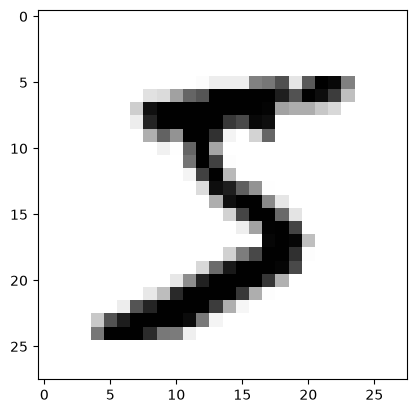

In [24]:
plotDigit(x_train[0])

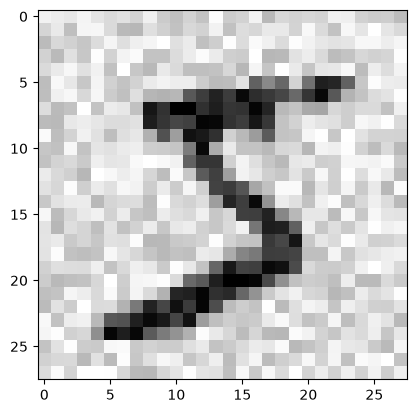

In [25]:
plotDigit(x_train_mod[0])

In [26]:
noise_x = x_train_mod
noise_y = x_train



In [27]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(noise_x, noise_y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([0.]), array([0.]), array([0.]), array([0.]), ...]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


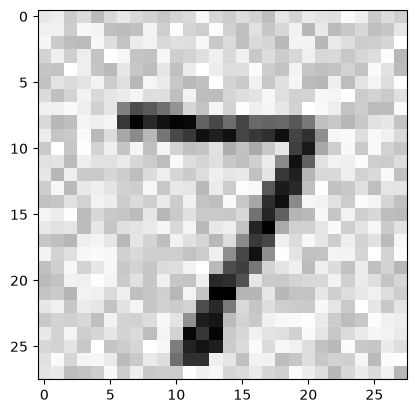

In [28]:
plotDigit(x_test_mod[0])

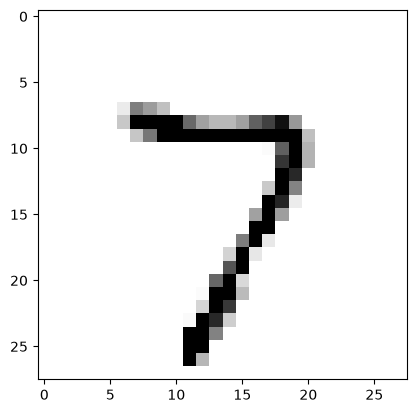

In [30]:
pred = knn.predict(x_test_mod[0].reshape(1,-1))
plotDigit(pred)